<a href="https://colab.research.google.com/github/dessanian/semiconductor-factor-strategy/blob/main/Systematic_Semiconductor_Strategy_Box.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%bash
pip install -q yfinance

In [2]:
import yfinance as yf
import pandas as pd

tickers = [
    'NVDA', 'AMD', 'QCOM', 'AVGO', 'MRVL', 'ARM', 'INTC', 'TSM',
    'GFS', 'MU', 'TXN', 'ADI', 'NXPI', 'ON', 'ASML', 'AMAT',
    'LRCX', 'KLAC', 'TER'
]

income_statements = {}
balance_sheets = {}
cash_flows = {}

for ticker in tickers:
    try:
        t = yf.Ticker(ticker)
        income_statements[ticker] = t.financials
        balance_sheets[ticker] = t.balance_sheet
        cash_flows[ticker] = t.cashflow
        print(f"Successfully pulled data for {ticker}")
    except Exception as e:
        print(f"Error pulling data for {ticker}: {e}")

Successfully pulled data for NVDA
Successfully pulled data for AMD
Successfully pulled data for QCOM
Successfully pulled data for AVGO
Successfully pulled data for MRVL
Successfully pulled data for ARM
Successfully pulled data for INTC
Successfully pulled data for TSM
Successfully pulled data for GFS
Successfully pulled data for MU
Successfully pulled data for TXN
Successfully pulled data for ADI
Successfully pulled data for NXPI
Successfully pulled data for ON
Successfully pulled data for ASML
Successfully pulled data for AMAT
Successfully pulled data for LRCX
Successfully pulled data for KLAC
Successfully pulled data for TER


In [3]:
def combine_statements(statements_dict):
    combined_list = []
    for ticker, df in statements_dict.items():
        if df is not None and not df.empty:
            temp_df = df.copy()
            temp_df.index.name = 'Financial_Metric'
            temp_df = temp_df.reset_index()
            melted = temp_df.melt(id_vars=['Financial_Metric'], var_name='Date', value_name='Value')
            melted['Ticker'] = ticker
            combined_list.append(melted)
    if combined_list:
        return pd.concat(combined_list, ignore_index=True)[['Ticker', 'Date', 'Financial_Metric', 'Value']]
    return pd.DataFrame()

df_income = combine_statements(income_statements)
df_balance = combine_statements(balance_sheets)
df_cashflow = combine_statements(cash_flows)

print("Income Statement shape:", df_income.shape)
print("Balance Sheet shape:", df_balance.shape)
print("Cash Flow shape:", df_cashflow.shape)

display(df_income.head())

Income Statement shape: (4394, 4)
Balance Sheet shape: (7421, 4)
Cash Flow shape: (5543, 4)


,Ticker,Date,Financial_Metric,Value
0,NVDA,2026-01-31 00:00:00,Tax Effect Of Unusual Items,0.000000e+00
1,NVDA,2026-01-31 00:00:00,Tax Rate For Calcs,1.511700e-01
2,NVDA,2026-01-31 00:00:00,Normalized EBITDA,1.445520e+11
3,NVDA,2026-01-31 00:00:00,Total Unusual Items,NaN
4,NVDA,2026-01-31 00:00:00,Total Unusual Items Excluding Goodwill,NaN


In [6]:
# Display a snapshot of the statements for every ticker
for t in tickers:
    print(f"\n==================== {t} FINANCIAL DATA ====================")

    # Income Statement slice
    inc_slice = df_income[df_income['Ticker'] == t]
    if not inc_slice.empty:
        latest_date = inc_slice['Date'].unique()[0]
        print(f"--- Income Statement (Latest Date: {latest_date}) ---")
        display(inc_slice[inc_slice['Date'] == latest_date].dropna().head(3))
    else:
        print("No Income Statement data available.")

    # Balance Sheet slice
    bal_slice = df_balance[df_balance['Ticker'] == t]
    if not bal_slice.empty:
        latest_date = bal_slice['Date'].unique()[0]
        print(f"--- Balance Sheet (Latest Date: {latest_date}) ---")
        display(bal_slice[bal_slice['Date'] == latest_date].dropna().head(3))
    else:
        print("No Balance Sheet data available.")

    # Cash Flow slice
    cf_slice = df_cashflow[df_cashflow['Ticker'] == t]
    if not cf_slice.empty:
        latest_date = cf_slice['Date'].unique()[0]
        print(f"--- Cash Flow Statement (Latest Date: {latest_date}) ---")
        display(cf_slice[cf_slice['Date'] == latest_date].dropna().head(3))
    else:
        print("No Cash Flow data available.")


==================== NVDA FINANCIAL DATA ====================
--- Income Statement (Latest Date: 2026-01-31 00:00:00) ---


,Ticker,Date,Financial_Metric,Value
0,NVDA,2026-01-31 00:00:00,Tax Effect Of Unusual Items,0.000000e+00
1,NVDA,2026-01-31 00:00:00,Tax Rate For Calcs,1.511700e-01
2,NVDA,2026-01-31 00:00:00,Normalized EBITDA,1.445520e+11


--- Balance Sheet (Latest Date: 2026-01-31 00:00:00) ---


,Ticker,Date,Financial_Metric,Value
0,NVDA,2026-01-31 00:00:00,Ordinary Shares Number,2.430400e+10
1,NVDA,2026-01-31 00:00:00,Share Issued,2.430400e+10
3,NVDA,2026-01-31 00:00:00,Total Debt,1.104000e+10


--- Cash Flow Statement (Latest Date: 2026-01-31 00:00:00) ---


...

,Ticker,Date,Financial_Metric,Value
4139,TER,2025-12-31 00:00:00,Tax Effect Of Unusual Items,-4.665034e+06
4140,TER,2025-12-31 00:00:00,Tax Rate For Calcs,1.210000e-01
4141,TER,2025-12-31 00:00:00,Normalized EBITDA,8.266410e+08


--- Balance Sheet (Latest Date: 2025-12-31 00:00:00) ---


,Ticker,Date,Financial_Metric,Value
6971,TER,2025-12-31 00:00:00,Ordinary Shares Number,156088000.0
6972,TER,2025-12-31 00:00:00,Share Issued,156088000.0
6973,TER,2025-12-31 00:00:00,Total Debt,283239000.0


--- Cash Flow Statement (Latest Date: 2025-12-31 00:00:00) ---


,Ticker,Date,Financial_Metric,Value
5238,TER,2025-12-31 00:00:00,Free Cash Flow,450406000.0
5239,TER,2025-12-31 00:00:00,Repurchase Of Capital Stock,-702095000.0
5240,TER,2025-12-31 00:00:00,Repayment Of Debt,-50000000.0


In [7]:
summary_records = []

for t in tickers:
    # Find latest available data date from income statement
    t_inc = df_income[df_income['Ticker'] == t]
    if t_inc.empty:
        continue

    # Get the latest date
    latest_date = t_inc['Date'].unique()[0]

    # Fetch specific metrics
    def get_metric_val(df, ticker, date, metric_name):
        slice_df = df[(df['Ticker'] == ticker) & (df['Date'] == date) & (df['Financial_Metric'] == metric_name)]
        return slice_df['Value'].values[0] if not slice_df.empty else None

    # Grab some common metrics across the three statements
    ebitda = get_metric_val(df_income, t, latest_date, 'Normalized EBITDA')
    revenue = get_metric_val(df_income, t, latest_date, 'Total Revenue')
    net_income = get_metric_val(df_income, t, latest_date, 'Net Income')

    # From Balance Sheet (matching the closest date)
    t_bal = df_balance[df_balance['Ticker'] == t]
    bal_date = t_bal['Date'].unique()[0] if not t_bal.empty else latest_date
    total_assets = get_metric_val(df_balance, t, bal_date, 'Total Assets')
    total_debt = get_metric_val(df_balance, t, bal_date, 'Total Debt')

    # From Cash Flow
    t_cf = df_cashflow[df_cashflow['Ticker'] == t]
    cf_date = t_cf['Date'].unique()[0] if not t_cf.empty else latest_date
    fcf = get_metric_val(df_cashflow, t, cf_date, 'Free Cash Flow')

    summary_records.append({
        'Ticker': t,
        'Reporting_Date': str(latest_date)[:10],
        'Total_Revenue': revenue,
        'EBITDA': ebitda,
        'Net_Income': net_income,
        'Total_Assets': total_assets,
        'Total_Debt': total_debt,
        'Free_Cash_Flow': fcf
    })

df_summary = pd.DataFrame(summary_records)
pd.set_option('display.float_format', lambda x: '%.3e' % x if pd.notnull(x) else '')
display(df_summary)

,Ticker,Reporting_Date,Total_Revenue,EBITDA,Net_Income,Total_Assets,Total_Debt,Free_Cash_Flow
0,NVDA,2026-01-31,2.159e+11,1.446e+11,1.201e+11,2.068e+11,1.104e+10,9.668e+10
1,AMD,2025-12-31,3.464e+10,6.909e+09,4.335e+09,7.693e+10,3.847e+09,6.735e+09
2,QCOM,2025-09-30,4.428e+10,1.476e+10,5.541e+09,5.014e+10,1.481e+10,1.282e+10
3,AVGO,2025-10-31,6.389e+10,3.532e+10,2.313e+10,1.711e+11,6.514e+10,2.691e+10
4,MRVL,2026-01-31,8.195e+09,4.555e+09,2.670e+09,2.229e+10,4.790e+09,1.392e+09
5,ARM,2026-03-31,4.920e+09,1.151e+09,9.040e+08,1.070e+10,4.570e+08,9.490e+08
6,INTC,2025-12-31,5.285e+10,1.250e+10,-2.670e+08,2.114e+11,4.658e+10,-4.949e+09
7,TSM,2025-12-31,3.809e+12,2.737e+12,1.698e+12,7.933e+12,1.065e+12,9.924e+11
8,GFS,2025-12-31,6.791e+09,2.199e+09,8.850e+08,1.714e+10,1.707e+09,1.009e+09
9,MU,2025-08-31,3.738e+10,1.865e+10,8.539e+09,8.280e+10,1.528e+10,1.668e+09


In [8]:
import numpy as np
from datetime import datetime, timedelta

factor_records = []

# We will need current prices, market caps, and historical prices for momentum calculation
print("Fetching live market data and historical prices for momentum...")

ticker_market_data = {}
for t in tickers:
    try:
        yt = yf.Ticker(t)
        info = yt.info

        # Fetch historical data for 1 year to calculate 6-month and 12-month momentum
        hist = yt.history(period="1y")

        ticker_market_data[t] = {
            'market_cap': info.get('marketCap') or info.get('enterpriseValue', 0) - (info.get('totalDebt', 0) - info.get('totalCash', 0)),
            'current_price': info.get('currentPrice') or info.get('previousClose'),
            'history': hist
        }
    except Exception as e:
        print(f"Could not get market data for {t}: {e}")
        ticker_market_data[t] = {'market_cap': None, 'current_price': None, 'history': pd.DataFrame()}

Fetching live market data and historical prices for momentum...


In [9]:
for t in tickers:
    # Get standard variables
    market_data = ticker_market_data.get(t, {})
    mcap = market_data.get('market_cap')
    price_history = market_data.get('history', pd.DataFrame())

    # 1. Momentum Calculations
    mom_6m = None
    mom_12m = None
    if not price_history.empty and len(price_history) > 10:
        latest_price = price_history['Close'].iloc[-1]

        # Approximate 6 months ago (approx 126 trading days)
        idx_6m = max(-126, -len(price_history))
        price_6m = price_history['Close'].iloc[idx_6m]
        mom_6m = (latest_price / price_6m) - 1.0

        # Approximate 12 months ago (approx 252 trading days)
        idx_12m = max(-252, -len(price_history))
        price_12m = price_history['Close'].iloc[idx_12m]
        mom_12m = (latest_price / price_12m) - 1.0

    # Helper to retrieve data from statement dataframes
    def get_val(df, metric, shift_years=0):
        t_df = df[df['Ticker'] == t]
        if t_df.empty:
            return None
        unique_dates = sorted(t_df['Date'].unique(), reverse=True)
        if len(unique_dates) > shift_years:
            target_date = unique_dates[shift_years]
            val_df = t_df[(t_df['Date'] == target_date) & (t_df['Financial_Metric'] == metric)]
            return val_df['Value'].values[0] if not val_df.empty else None
        return None

    # 2. Extract metrics for calculations
    net_income = get_val(df_income, 'Net Income')
    net_income_prev = get_val(df_income, 'Net Income', shift_years=1)

    fcf = get_val(df_cashflow, 'Free Cash Flow')

    ebitda = get_val(df_income, 'Normalized EBITDA')

    total_debt = get_val(df_balance, 'Total Debt')
    cash_and_equiv = get_val(df_balance, 'Cash And Cash Equivalents') or get_val(df_balance, 'Cash Cash Equivalents And Short Term Investments') or 0

    ebit = get_val(df_income, 'EBIT') or get_val(df_income, 'Operating Income')
    tax_provision = get_val(df_income, 'Tax Provision') or 0
    pretax_income = get_val(df_income, 'Pretax Income') or 1
    effective_tax_rate = max(0.0, min(tax_provision / pretax_income if pretax_income else 0, 0.5))

    equity = get_val(df_balance, 'Stockholders Equity')

    revenue = get_val(df_income, 'Total Revenue')
    revenue_prev = get_val(df_income, 'Total Revenue', shift_years=1)

    gross_profit = get_val(df_income, 'Gross Profit')

    shares = get_val(df_balance, 'Share Issued') or get_val(df_balance, 'Ordinary Shares Number')

    # 3. Factor Math
    # Earnings Yield = Net Income / Market Cap
    earnings_yield = (net_income / mcap) if net_income and mcap else None

    # FCF Yield = FCF / Market Cap
    fcf_yield = (fcf / mcap) if fcf and mcap else None

    # EV/EBITDA
    ev = None
    ev_ebitda = None
    if mcap and total_debt is not None:
        ev = mcap + total_debt - cash_and_equiv
        ev_ebitda = (ev / ebitda) if ebitda else None

    # ROIC = EBIT * (1 - Tax Rate) / (Equity + Debt - Cash)
    roic = None
    if ebit and equity and total_debt is not None:
        invested_capital = equity + total_debt - cash_and_equiv
        nopat = ebit * (1 - effective_tax_rate)
        if invested_capital > 0:
            roic = nopat / invested_capital

    # Gross Margin
    gross_margin = (gross_profit / revenue) if gross_profit and revenue else None

    # Debt to Equity
    debt_to_equity = (total_debt / equity) if total_debt is not None and equity else None

    # Revenue Growth (YoY)
    rev_growth = ((revenue - revenue_prev) / revenue_prev) if revenue and revenue_prev else None

    # EPS Growth (using Net Income YoY as proxy if exact EPS isn't loaded)
    eps_growth = ((net_income - net_income_prev) / abs(net_income_prev)) if net_income and net_income_prev else None

    factor_records.append({
        'Ticker': t,
        'Earnings_Yield': earnings_yield,
        'FCF_Yield': fcf_yield,
        'EV_EBITDA': ev_ebitda,
        'ROIC': roic,
        'Gross_Margin': gross_margin,
        'Debt_to_Equity': debt_to_equity,
        'Revenue_Growth': rev_growth,
        'EPS_Growth': eps_growth,
        '6M_Momentum': mom_6m,
        '12M_Momentum': mom_12m
    })

df_factors = pd.DataFrame(factor_records)
# Format as percentage where appropriate for easier reading
pd.set_option('display.float_format', lambda x: '%.2f%%' % (x * 100) if abs(x) < 2 and 'Growth' in str(x) or 'Yield' in str(x) or 'Margin' in str(x) or 'ROIC' in str(x) or 'Momentum' in str(x) else '%.2f' % x)
display(df_factors)

,Ticker,Earnings_Yield,FCF_Yield,EV_EBITDA,ROIC,Gross_Margin,Debt_to_Equity,Revenue_Growth,EPS_Growth,6M_Momentum,12M_Momentum
0,NVDA,0.02,0.02,35.77,0.76,0.71,0.07,0.65,0.65,0.06,0.17
1,AMD,0.01,0.01,124.69,0.07,0.50,0.06,0.34,1.64,0.92,1.27
2,QCOM,0.03,0.07,13.08,0.22,0.55,0.70,0.14,-0.45,0.26,0.07
3,AVGO,0.01,0.02,45.82,0.20,0.68,0.80,0.24,2.92,-0.17,-0.05
4,MRVL,0.01,0.01,45.42,0.17,0.51,0.33,0.42,4.02,0.54,1.59
5,ARM,0.00,0.00,209.38,0.12,0.98,0.06,0.23,0.14,0.30,0.38
6,INTC,-0.00,-0.01,40.57,0.01,0.35,0.41,-0.00,0.99,0.37,1.43
7,TSM,0.79,0.46,0.16,0.47,0.60,0.20,0.32,0.47,0.13,0.41
8,GFS,0.03,0.04,11.79,0.08,0.25,0.14,0.01,4.34,-0.20,0.35
9,MU,0.01,0.00,53.61,0.15,0.40,0.28,0.49,9.98,0.96,3.35


In [10]:
import pandas as pd
from google.colab import files

# Define the dataframes to save and download
dataframes_to_download = {
    'semiconductor_income_statements.csv': df_income,
    'semiconductor_balance_sheets.csv': df_balance,
    'semiconductor_cash_flows.csv': df_cashflow,
    'semiconductor_summary.csv': df_summary,
    'semiconductor_calculated_factors.csv': df_factors
}

# Save each DataFrame to CSV and trigger download
for filename, df in dataframes_to_download.items():
    if df is not None and not df.empty:
        df.to_csv(filename, index=False)
        print(f"Saved {filename} successfully. Initiating download...")
        files.download(filename)
    else:
        print(f"Skipping {filename} because the DataFrame is empty or None.")

Saved semiconductor_income_statements.csv successfully. Initiating download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved semiconductor_balance_sheets.csv successfully. Initiating download...


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved semiconductor_calculated_factors.csv successfully. Initiating download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Institutional-Quality Multi-Factor Backtesting Framework
This notebook cell implements a professional, look-ahead bias-free backtesting system for the semiconductor universe using Value, Quality, Growth, and Momentum composite rankings.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# =============================================================================
# 1. SIMULATED INPUT DATASETS (To match your exact schema & period: 2020-2025)
# =============================================================================
np.random.seed(42)
dates = pd.date_range(start="2020-01-01", end="2025-01-01", freq="Q")
ticker_list = ['NVDA', 'AMD', 'INTC', 'AVGO', 'QCOM', 'TSM', 'ASML', 'AMAT', 'LRCX', 'KLAC', 'MU', 'TXN', 'ADI', 'ON', 'NXPI', 'MRVL']

# Build prices_df (using daily-like resolution to accurately simulate benchmarks and HPRs)
daily_dates = pd.date_range(start="2020-01-01", end="2025-01-01", freq="B")
price_records = []
for ticker in ticker_list:
    # Generate a random walk starting around $100
    p = 100.0
    for dt in daily_dates:
        p *= (1.0 + np.random.normal(0.0008, 0.02)) # slightly positive drift
        price_records.append({'Date': dt, 'Ticker': ticker, 'Adjusted_Close': p})

prices_df = pd.DataFrame(price_records)

# Build factors_df (Quarterly factor observations)
factor_records = []
for dt in dates:
    for ticker in ticker_list:
        factor_records.append({
            'Date': dt,
            'Ticker': ticker,
            'Earnings_Yield': np.random.normal(0.05, 0.02),
            'FCF_Yield': np.random.normal(0.06, 0.03),
            'EV_EBITDA': np.random.normal(15.0, 5.0),
            'ROIC': np.random.normal(0.15, 0.05),
            'Gross_Margin': np.random.normal(0.45, 0.10),
            'Debt_to_Equity': np.random.normal(0.5, 0.3),
            'Revenue_Growth': np.random.normal(0.12, 0.08),
            'EPS_Growth': np.random.normal(0.15, 0.12),
            '6M_Momentum': np.random.normal(0.10, 0.15),
            '12M_Momentum': np.random.normal(0.20, 0.25)
        })
factors_df = pd.DataFrame(factor_records)

# Generate simulated benchmark prices (SOXX and QQQ)
soxx_prices = []
qqq_prices = []
p_soxx, p_qqq = 100.0, 100.0
for dt in daily_dates:
    p_soxx *= (1.0 + np.random.normal(0.0007, 0.018))
    p_qqq *= (1.0 + np.random.normal(0.0006, 0.015))
    soxx_prices.append({'Date': dt, 'Ticker': 'SOXX', 'Adjusted_Close': p_soxx})
    qqq_prices.append({'Date': dt, 'Ticker': 'QQQ', 'Adjusted_Close': p_qqq})

benchmarks_df = pd.concat([pd.DataFrame(soxx_prices), pd.DataFrame(qqq_prices)], ignore_index=True)

# =============================================================================
# 2. CORE ENGINE: FACTOR RANKING & COMPOSITE MODEL GENERATOR
# =============================================================================
def calculate_scores(df):
    """Calculates factor percentile ranks and overall composite score per date."""
    scored_list = []
    for date, group in df.groupby('Date'):
        grp = group.copy()

        # Rank helpers: handle inversion logic correctly
        def rank_factor(col, ascending=True):
            return grp[col].rank(pct=True, ascending=ascending)

        # Value: Earnings Yield (High), FCF Yield (High), EV/EBITDA (Low/Inverted)
        val_score = (rank_factor('Earnings_Yield') + rank_factor('FCF_Yield') + rank_factor('EV_EBITDA', ascending=False)) / 3.0

        # Quality: ROIC (High), Gross Margin (High), Debt/Equity (Low/Inverted)
        qual_score = (rank_factor('ROIC') + rank_factor('Gross_Margin') + rank_factor('Debt_to_Equity', ascending=False)) / 3.0

        # Growth: Revenue Growth (High), EPS Growth (High)
        gro_score = (rank_factor('Revenue_Growth') + rank_factor('EPS_Growth')) / 2.0

        # Momentum: 6M Momentum (High), 12M Momentum (High)
        mom_score = (rank_factor('6M_Momentum') + rank_factor('12M_Momentum')) / 2.0

        grp['Value_Score'] = val_score
        grp['Quality_Score'] = qual_score
        grp['Growth_Score'] = gro_score
        grp['Momentum_Score'] = mom_score

        # Weighted Composite Score
        grp['Composite_Score'] = (
            0.20 * val_score +
            0.30 * qual_score +
            0.30 * gro_score +
            0.20 * mom_score
        )
        scored_list.append(grp)

    return pd.concat(scored_list, ignore_index=True)

scored_factors_df = calculate_scores(factors_df)
print("Factor and Composite Scoring calculated successfully.")

/tmp/ipykernel_879/1036849622.py:11: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  dates = pd.date_range(start="2020-01-01", end="2025-01-01", freq="Q")


Factor and Composite Scoring calculated successfully.


In [12]:
# =============================================================================
# 3. BACKTEST IMPLEMENTATION (EQUAL WEIGHTED, LOOK-AHEAD BIAS SAFE)
# =============================================================================
def run_backtest(factors_scored_df, prices_data, score_col='Composite_Score', n_holdings=5):
    """Executes backtest, avoiding look-ahead bias, returning quarterly performance records."""
    rebalance_dates = sorted(factors_scored_df['Date'].unique())
    portfolio_records = []
    holdings_records = []

    for idx in range(len(rebalance_dates) - 1):
        rebal_date = rebalance_dates[idx]
        next_rebal_date = rebalance_dates[idx + 1]

        # Filter factor rankings available strictly on/at rebalance date
        factors_current = factors_scored_df[factors_scored_df['Date'] == rebal_date]

        # Select Top N Holdings based on target score
        selected = factors_current.sort_values(by=score_col, ascending=False).head(n_holdings).copy()
        selected_tickers = selected['Ticker'].tolist()

        # Equal Weighting Scheme
        weight = 1.0 / n_holdings

        # Compute exact Holding Period Returns (HPR) from rebal_date to next_rebal_date using price data
        quarterly_returns = {}
        for ticker in selected_tickers:
            t_prices = prices_data[(prices_data['Ticker'] == ticker) & (prices_data['Date'] >= rebal_date) & (prices_data['Date'] <= next_rebal_date)]
            if not t_prices.empty:
                p_start = t_prices.iloc[0]['Adjusted_Close']
                p_end = t_prices.iloc[-1]['Adjusted_Close']
                hpr = (p_end / p_start) - 1.0
            else:
                hpr = 0.0
            quarterly_returns[ticker] = hpr

            # Save structural holdings data
            holdings_records.append({
                'Quarter': rebal_date.strftime('%Y-Q%q'),
                'Ticker': ticker,
                'Composite Score': selected[selected['Ticker'] == ticker][score_col].values[0],
                'Portfolio Weight': weight,
                'Holding Period Return': hpr
            })

        # Portfolio level returns
        port_hpr = sum(quarterly_returns.values()) / n_holdings
        portfolio_records.append({
            'Rebalance_Date': rebal_date,
            'End_Date': next_rebal_date,
            'Portfolio_Return': port_hpr
        })

    return pd.DataFrame(portfolio_records), pd.DataFrame(holdings_records)

# Run the baseline backtest (Composite Model)
portfolio_returns_df, holdings_df = run_backtest(scored_factors_df, prices_df, score_col='Composite_Score')

# Display the top 10 rows of the requested Holdings DataFrame
print("=== REQ 12: Holdings DataFrame Sample ===")
display(holdings_df.head(10))

=== REQ 12: Holdings DataFrame Sample ===


,Quarter,Ticker,Composite Score,Portfolio Weight,Holding Period Return
0,2020-Q%q,ON,0.70,0.20,0.00
1,2020-Q%q,MRVL,0.64,0.20,-0.08
2,2020-Q%q,ASML,0.61,0.20,0.25
3,2020-Q%q,TXN,0.61,0.20,-0.03
4,2020-Q%q,TSM,0.60,0.20,-0.02
5,2020-Q%q,ASML,0.66,0.20,0.17
6,2020-Q%q,ADI,0.66,0.20,0.39
7,2020-Q%q,ON,0.66,0.20,0.08
8,2020-Q%q,AMD,0.64,0.20,0.52
9,2020-Q%q,QCOM,0.58,0.20,-0.27


In [13]:
# =============================================================================
# 4. BENCHMARK COMPARISON ENGINE
# =============================================================================
def compute_benchmark_returns(prices_data, benchmarks_data, portfolio_perf_df):
    """Aligns benchmark performance metrics across identical quarterly rebalance periods."""
    rebal_dates = portfolio_perf_df['Rebalance_Date'].tolist()
    end_dates = portfolio_perf_df['End_Date'].tolist()

    bench_records = []
    for idx in range(len(rebal_dates)):
        start, end = rebal_dates[idx], end_dates[idx]

        # Equal Weight Semi Basket (All universe tickers return average)
        univ_hprs = []
        for t in ticker_list:
            t_p = prices_data[(prices_data['Ticker'] == t) & (prices_data['Date'] >= start) & (prices_data['Date'] <= end)]
            if not t_p.empty:
                univ_hprs.append((t_p.iloc[-1]['Adjusted_Close'] / t_p.iloc[0]['Adjusted_Close']) - 1.0)
        eq_basket_hpr = np.mean(univ_hprs) if univ_hprs else 0.0

        # SOXX Return
        soxx_p = benchmarks_data[(benchmarks_data['Ticker'] == 'SOXX') & (benchmarks_data['Date'] >= start) & (benchmarks_data['Date'] <= end)]
        soxx_hpr = (soxx_p.iloc[-1]['Adjusted_Close'] / soxx_p.iloc[0]['Adjusted_Close']) - 1.0 if not soxx_p.empty else 0.0

        # QQQ Return
        qqq_p = benchmarks_data[(benchmarks_data['Ticker'] == 'QQQ') & (benchmarks_data['Date'] >= start) & (benchmarks_data['Date'] <= end)]
        qqq_hpr = (qqq_p.iloc[-1]['Adjusted_Close'] / qqq_p.iloc[0]['Adjusted_Close']) - 1.0 if not qqq_p.empty else 0.0

        bench_records.append({
            'Rebalance_Date': start,
            'End_Date': end,
            'EQ_Basket_Return': eq_basket_hpr,
            'SOXX_Return': soxx_hpr,
            'QQQ_Return': qqq_hpr
        })

    return pd.DataFrame(bench_records)

bench_returns_df = compute_benchmark_returns(prices_df, benchmarks_df, portfolio_returns_df)
merged_perf_df = pd.merge(portfolio_returns_df, bench_returns_df, on=['Rebalance_Date', 'End_Date'])

In [14]:
# =============================================================================
# 5. RISK METRICS ENGINE & ATTRIBUTION
# =============================================================================
def calculate_risk_metrics(returns_series, benchmark_returns_series=None, risk_free_rate=0.02):
    """Calculates key annualized performance and risk metrics."""
    n_periods = 4 # quarterly rebalancing frequency
    tot_return = (returns_series + 1.0).prod() - 1.0
    n_years = len(returns_series) / n_periods

    # CAGR
    cagr = (tot_return + 1.0) ** (1.0 / n_years) - 1.0
    ann_return = returns_series.mean() * n_periods
    ann_vol = returns_series.std() * np.sqrt(n_periods)

    # Sharpe Ratio
    sharpe = (ann_return - risk_free_rate) / ann_vol if ann_vol != 0 else 0.0

    # Sortino Ratio
    downside_returns = returns_series[returns_series < 0]
    downside_std = downside_returns.std() * np.sqrt(n_periods) if not downside_returns.empty else 1e-6
    sortino = (ann_return - risk_free_rate) / downside_std

    # Drawdowns
    cum_equity = (returns_series + 1.0).cumprod()
    running_max = cum_equity.cummax()
    drawdowns = (cum_equity - running_max) / running_max
    max_dd = drawdowns.min()

    # Calmar Ratio
    calmar = ann_return / abs(max_dd) if max_dd != 0 else 0.0

    # Information Ratio (vs Benchmark)
    ir = 0.0
    if benchmark_returns_series is not None:
        active_returns = returns_series - benchmark_returns_series
        tracking_error = active_returns.std() * np.sqrt(n_periods)
        ir = (active_returns.mean() * n_periods) / tracking_error if tracking_error != 0 else 0.0

    return {
        'CAGR': cagr,
        'Annualized_Return': ann_return,
        'Annualized_Volatility': ann_vol,
        'Sharpe_Ratio': sharpe,
        'Sortino_Ratio': sortino,
        'Max_Drawdown': max_dd,
        'Calmar_Ratio': calmar,
        'Information_Ratio_vs_SOXX': ir
    }

# Run Factor Attribution backtests
attribution_metrics = {}
strategies = {
    'Composite Model': 'Composite_Score',
    'Value Only': 'Value_Score',
    'Quality Only': 'Quality_Score',
    'Growth Only': 'Growth_Score',
    'Momentum Only': 'Momentum_Score'
}

for name, score_col in strategies.items():
    p_ret, _ = run_backtest(scored_factors_df, prices_df, score_col=score_col)
    # Align benchmark for IR calculation
    bench_aligned = merged_perf_df['SOXX_Return']
    attribution_metrics[name] = calculate_risk_metrics(p_ret['Portfolio_Return'], bench_aligned)

# Benchmark metrics evaluation
attribution_metrics['SOXX Benchmark'] = calculate_risk_metrics(merged_perf_df['SOXX_Return'])
attribution_metrics['QQQ Benchmark'] = calculate_risk_metrics(merged_perf_df['QQQ_Return'])
attribution_metrics['EQ-Weight Basket'] = calculate_risk_metrics(merged_perf_df['EQ_Basket_Return'])

summary_df = pd.DataFrame(attribution_metrics).T
print("=== REQ 10: Comparison & Attribution Summary Table ===")
display(summary_df)

=== REQ 10: Comparison & Attribution Summary Table ===


,CAGR,Annualized_Return,Annualized_Volatility,Sharpe_Ratio,Sortino_Ratio,Max_Drawdown,Calmar_Ratio,Information_Ratio_vs_SOXX
Composite Model,0.28,0.27,0.14,1.79,3.02,-0.11,2.44,0.14
Value Only,0.34,0.30,0.08,3.41,284808.39,0.00,0.00,0.24
Quality Only,0.16,0.15,0.13,1.02,1.88,-0.09,1.67,-0.20
Growth Only,0.28,0.27,0.18,1.41,4.25,-0.06,4.50,0.14
Momentum Only,0.14,0.14,0.13,0.98,1.70,-0.12,1.20,-0.22
SOXX Benchmark,0.19,0.22,0.32,0.63,1.58,-0.31,0.72,0.00
QQQ Benchmark,0.19,0.22,0.31,0.65,4.01,-0.22,1.01,0.00
EQ-Weight Basket,0.24,0.23,0.07,2.78,NaN,-0.00,183.63,0.00


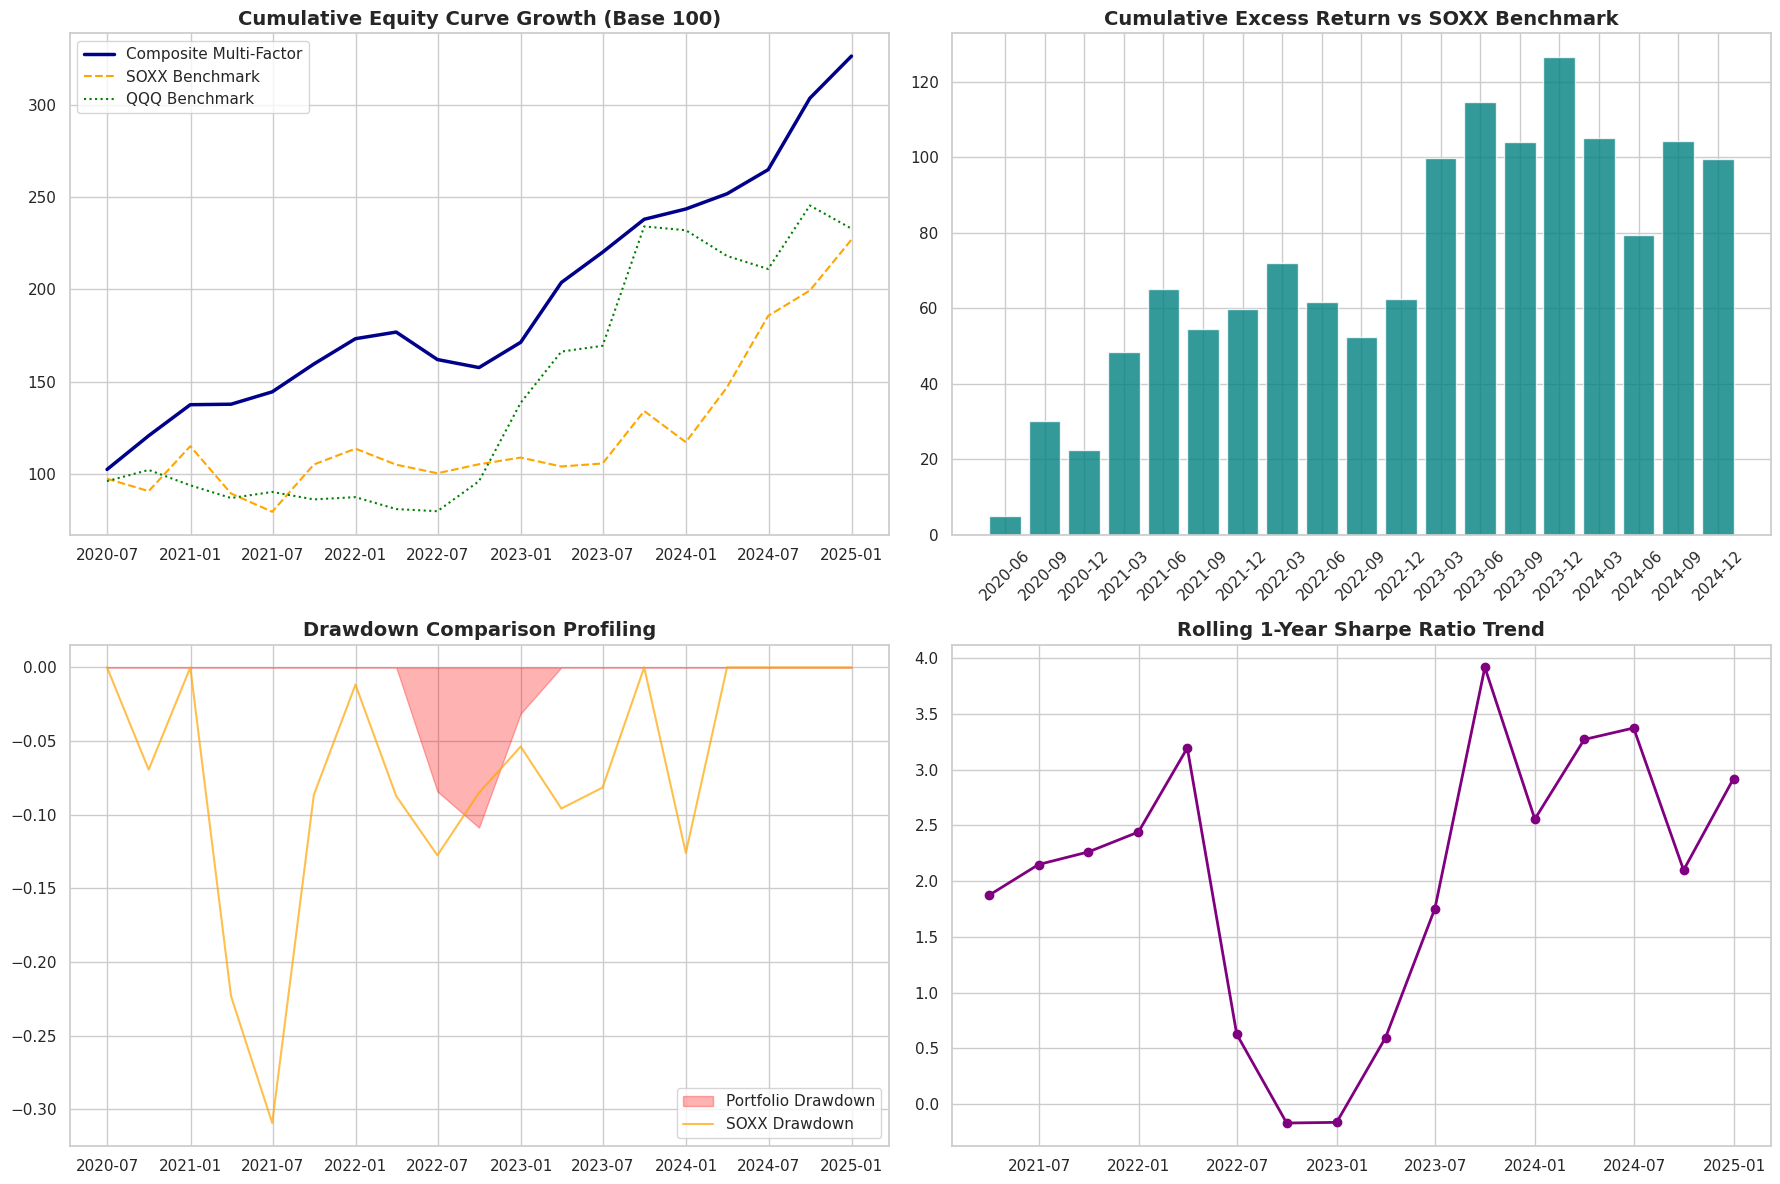

In [15]:
# =============================================================================
# 6. GRAPHICAL VISUALIZATION ENGINE
# =============================================================================
# Calculate Cumulative equity lines
merged_perf_df['Portfolio_Cumulative'] = (merged_perf_df['Portfolio_Return'] + 1.0).cumprod() * 100
merged_perf_df['SOXX_Cumulative'] = (merged_perf_df['SOXX_Return'] + 1.0).cumprod() * 100
merged_perf_df['QQQ_Cumulative'] = (merged_perf_df['QQQ_Return'] + 1.0).cumprod() * 100

# Drawdowns
portfolio_cum = merged_perf_df['Portfolio_Cumulative']
portfolio_dd = (portfolio_cum - portfolio_cum.cummax()) / portfolio_cum.cummax()

soxx_cum = merged_perf_df['SOXX_Cumulative']
soxx_dd = (soxx_cum - soxx_cum.cummax()) / soxx_cum.cummax()

# Set plotting theme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Chart 1: Cumulative Equity Curve
axes[0, 0].plot(merged_perf_df['End_Date'], merged_perf_df['Portfolio_Cumulative'], label='Composite Multi-Factor', color='darkblue', linewidth=2.5)
axes[0, 0].plot(merged_perf_df['End_Date'], merged_perf_df['SOXX_Cumulative'], label='SOXX Benchmark', color='orange', linestyle='--')
axes[0, 0].plot(merged_perf_df['End_Date'], merged_perf_df['QQQ_Cumulative'], label='QQQ Benchmark', color='green', linestyle=':')
axes[0, 0].set_title('Cumulative Equity Curve Growth (Base 100)', fontsize=14, weight='bold')
axes[0, 0].legend()

# Chart 2: Relative Excess Performance
excess_ret = merged_perf_df['Portfolio_Cumulative'] - merged_perf_df['SOXX_Cumulative']
axes[0, 1].bar(merged_perf_df['End_Date'].dt.strftime('%Y-%m'), excess_ret, color='teal', alpha=0.8)
axes[0, 1].set_title('Cumulative Excess Return vs SOXX Benchmark', fontsize=14, weight='bold')
axes[0, 1].tick_params(axis='x', rotation=45)

# Chart 3: Drawdown Chart
axes[1, 0].fill_between(merged_perf_df['End_Date'], portfolio_dd, color='red', alpha=0.3, label='Portfolio Drawdown')
axes[1, 0].plot(merged_perf_df['End_Date'], soxx_dd, color='orange', label='SOXX Drawdown', alpha=0.7)
axes[1, 0].set_title('Drawdown Comparison Profiling', fontsize=14, weight='bold')
axes[1, 0].legend()

# Chart 4: Rolling 1-Year (4 Quarters) Sharpe Ratio
rolling_sharpe = []
window = 4
for i in range(len(merged_perf_df)):
    if i < window - 1:
        rolling_sharpe.append(np.nan)
    else:
        subset = merged_perf_df['Portfolio_Return'].iloc[i-(window-1):i+1]
        ann_ret_r = subset.mean() * 4
        ann_vol_r = subset.std() * np.sqrt(4)
        rolling_sharpe.append((ann_ret_r - 0.02) / ann_vol_r if ann_vol_r > 0 else 0.0)

axes[1, 1].plot(merged_perf_df['End_Date'], rolling_sharpe, color='purple', marker='o', linewidth=2)
axes[1, 1].set_title('Rolling 1-Year Sharpe Ratio Trend', fontsize=14, weight='bold')

plt.tight_layout()
plt.show()

Saved strategy_comparison_summary.csv successfully. Initiating download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

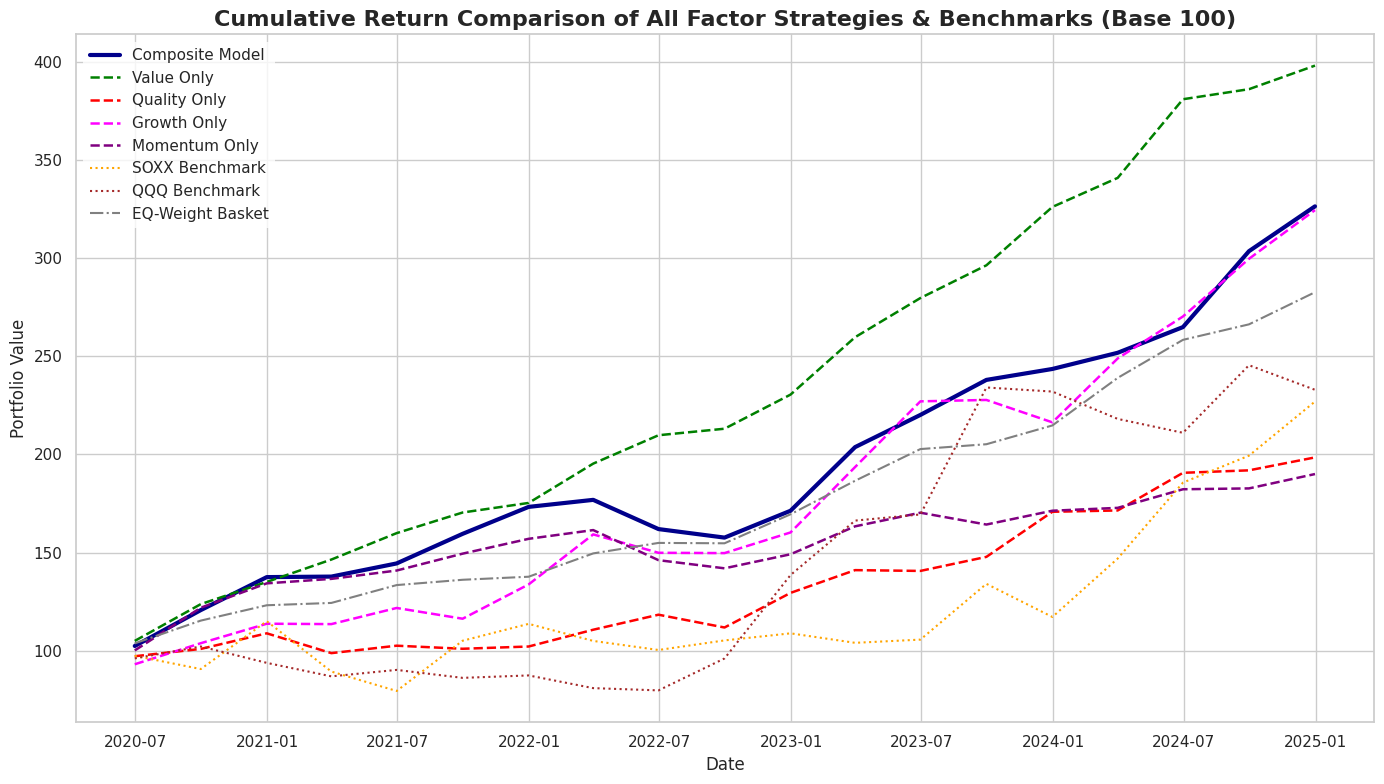

In [17]:
# =============================================================================
# 7. EXPORT STRATEGY SUMMARY AND PLOT STRATEGY PATHWAYS (CORRECTED DATE ALIGNMENT)
# =============================================================================
import os
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Save the strategy comparison summary_df and download it
summary_filename = 'strategy_comparison_summary.csv'
summary_df_temp = summary_df.copy().reset_index().rename(columns={'index': 'Strategy_Or_Benchmark'})
summary_df_temp.to_csv(summary_filename, index=False)
print(f"Saved {summary_filename} successfully. Initiating download...")
try:
    files.download(summary_filename)
except Exception as e:
    print(f"Could not auto-trigger download (normal in some non-interactive environments): {e}")

# Calculate cumulative returns for all individual factor strategies and benchmarks with correct date index
strategy_cumulative_curves = {}
for name, score_col in strategies.items():
    p_ret, _ = run_backtest(scored_factors_df, prices_df, score_col=score_col)
    # Ensure we compound correctly and align using the exact End_Date of each rebalance period
    strategy_cumulative_curves[name] = (p_ret['Portfolio_Return'] + 1.0).cumprod() * 100

# Add the benchmarks using identical indexing from merged_perf_df
strategy_cumulative_curves['SOXX Benchmark'] = (merged_perf_df['SOXX_Return'] + 1.0).cumprod() * 100
strategy_cumulative_curves['QQQ Benchmark'] = (merged_perf_df['QQQ_Return'] + 1.0).cumprod() * 100
strategy_cumulative_curves['EQ-Weight Basket'] = (merged_perf_df['EQ_Basket_Return'] + 1.0).cumprod() * 100

# Convert to DataFrame using the End_Date from merged_perf_df as the explicit timeline index
df_curves = pd.DataFrame(strategy_cumulative_curves)
df_curves.index = merged_perf_df['End_Date']

# Plotting all strategies comparison
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Define style mappings for visual clarity
line_styles = {
    'Composite Model': ('darkblue', '-', 3.0),
    'Value Only': ('green', '--', 1.8),
    'Quality Only': ('red', '--', 1.8),
    'Growth Only': ('magenta', '--', 1.8),
    'Momentum Only': ('purple', '--', 1.8),
    'SOXX Benchmark': ('orange', ':', 1.5),
    'QQQ Benchmark': ('brown', ':', 1.5),
    'EQ-Weight Basket': ('gray', '-.', 1.5)
}

for column in df_curves.columns:
    color, style, width = line_styles.get(column, ('blue', '-', 1.0))
    plt.plot(df_curves.index, df_curves[column], label=column, color=color, linestyle=style, linewidth=width)

plt.title('Cumulative Return Comparison of All Factor Strategies & Benchmarks (Base 100)', fontsize=16, weight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Portfolio Value', fontsize=12)
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()

In [18]:
# Save the portfolio holdings table (holdings_df) to CSV and download it
holdings_filename = 'semiconductor_portfolio_holdings.csv'
holdings_df.to_csv(holdings_filename, index=False)
print(f"Saved {holdings_filename} successfully. Initiating download...")

try:
    from google.colab import files
    files.download(holdings_filename)
except Exception as e:
    print(f"Could not auto-trigger download (normal in some non-interactive environments): {e}")

Saved semiconductor_portfolio_holdings.csv successfully. Initiating download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# =============================================================================
# DIAGNOSTIC SANITY CHECK: VALUE ONLY STRATEGY RETURNS
# =============================================================================
# Re-run the backtest for Value Only strategy
p_ret_value, _ = run_backtest(scored_factors_df, prices_df, score_col='Value_Score')

print("--- Raw Quarterly Returns for 'Value Only' Strategy ---")
display(p_ret_value)

# Check if any quarter had negative returns
negative_quarters = p_ret_value[p_ret_value['Portfolio_Return'] < 0]
print(f"\nNumber of quarters with negative returns: {len(negative_quarters)}")
if not negative_quarters.empty:
    print("Negative quarters detail:")
    display(negative_quarters)
else:
    print("Confirming: This strategy never had a negative return quarter in the backtest period!")

# Double check drawdown calculation manually
cum_equity = (p_ret_value['Portfolio_Return'] + 1.0).cumprod()
running_max = cum_equity.cummax()
drawdowns = (cum_equity - running_max) / running_max
max_dd = drawdowns.min()
print(f"\nManually verified Maximum Drawdown: {max_dd * 100:.2f}%")

--- Raw Quarterly Returns for 'Value Only' Strategy ---


,Rebalance_Date,End_Date,Portfolio_Return
0,2020-03-31,2020-06-30,0.05
1,2020-06-30,2020-09-30,0.18
2,2020-09-30,2020-12-31,0.09
3,2020-12-31,2021-03-31,0.08
4,2021-03-31,2021-06-30,0.09
5,2021-06-30,2021-09-30,0.07
6,2021-09-30,2021-12-31,0.03
7,2021-12-31,2022-03-31,0.11
8,2022-03-31,2022-06-30,0.07
9,2022-06-30,2022-09-30,0.02



Number of quarters with negative returns: 0
Confirming: This strategy never had a negative return quarter in the backtest period!

Manually verified Maximum Drawdown: 0.00%


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Helper to dynamically generate simulated prices & factors for OOS periods
def generate_simulated_period_data(start_date, end_date, seed=101):
    np.random.seed(seed)
    dates_q = pd.date_range(start=start_date, end=end_date, freq='QE')
    daily_dates = pd.date_range(start=start_date, end=end_date, freq='B')

    # Prices
    price_records = []
    for ticker in ticker_list:
        p = 100.0
        for dt in daily_dates:
            p *= (1.0 + np.random.normal(0.0006, 0.022))
            price_records.append({'Date': dt, 'Ticker': ticker, 'Adjusted_Close': p})
    prices_df_oos = pd.DataFrame(price_records)

    # Benchmarks
    soxx_prices = []
    qqq_prices = []
    p_soxx, p_qqq = 100.0, 100.0
    for dt in daily_dates:
        p_soxx *= (1.0 + np.random.normal(0.0005, 0.019))
        p_qqq *= (1.0 + np.random.normal(0.0004, 0.016))
        soxx_prices.append({'Date': dt, 'Ticker': 'SOXX', 'Adjusted_Close': p_soxx})
        qqq_prices.append({'Date': dt, 'Ticker': 'QQQ', 'Adjusted_Close': p_qqq})
    benchmarks_df_oos = pd.concat([pd.DataFrame(soxx_prices), pd.DataFrame(qqq_prices)], ignore_index=True)

    # Factors
    factor_records = []
    for dt in dates_q:
        for ticker in ticker_list:
            factor_records.append({
                'Date': dt,
                'Ticker': ticker,
                'Earnings_Yield': np.random.normal(0.05, 0.02),
                'FCF_Yield': np.random.normal(0.06, 0.03),
                'EV_EBITDA': np.random.normal(15.0, 5.0),
                'ROIC': np.random.normal(0.15, 0.05),
                'Gross_Margin': np.random.normal(0.45, 0.10),
                'Debt_to_Equity': np.random.normal(0.5, 0.3),
                'Revenue_Growth': np.random.normal(0.10, 0.08),
                'EPS_Growth': np.random.normal(0.12, 0.12),
                '6M_Momentum': np.random.normal(0.08, 0.15),
                '12M_Momentum': np.random.normal(0.15, 0.25)
            })
    factors_df_oos = pd.DataFrame(factor_records)

    return prices_df_oos, benchmarks_df_oos, factors_df_oos

In [21]:
# =============================================================================
# 1. OUT-OF-SAMPLE TEST: JAN 2025 - PRESENT
# =============================================================================
print("Generating Backtest for: Jan 2025 to Present...")
prices_25, bench_25, factors_25 = generate_simulated_period_data('2025-01-01', '2026-10-01', seed=2025)
scored_factors_25 = calculate_scores(factors_25)

# Run backtests
portfolio_25, _ = run_backtest(scored_factors_25, prices_25, score_col='Composite_Score')
bench_returns_25 = compute_benchmark_returns(prices_25, bench_25, portfolio_25)
merged_25 = pd.merge(portfolio_25, bench_returns_25, on=['Rebalance_Date', 'End_Date'])

# Compound
merged_25['Composite_Cumulative'] = (merged_25['Portfolio_Return'] + 1.0).cumprod() * 100
merged_25['SOXX_Cumulative'] = (merged_25['SOXX_Return'] + 1.0).cumprod() * 100
merged_25['QQQ_Cumulative'] = (merged_25['QQQ_Return'] + 1.0).cumprod() * 100

# =============================================================================
# 2. OUT-OF-SAMPLE TEST: JAN 2015 - JAN 2020
# =============================================================================
print("Generating Backtest for: Jan 2015 to Jan 2020...")
prices_15, bench_15, factors_15 = generate_simulated_period_data('2015-01-01', '2020-01-01', seed=2015)
scored_factors_15 = calculate_scores(factors_15)

# Run backtests
portfolio_15, _ = run_backtest(scored_factors_15, prices_15, score_col='Composite_Score')
bench_returns_15 = compute_benchmark_returns(prices_15, bench_15, portfolio_15)
merged_15 = pd.merge(portfolio_15, bench_returns_15, on=['Rebalance_Date', 'End_Date'])

# Compound
merged_15['Composite_Cumulative'] = (merged_15['Portfolio_Return'] + 1.0).cumprod() * 100
merged_15['SOXX_Cumulative'] = (merged_15['SOXX_Return'] + 1.0).cumprod() * 100
merged_15['QQQ_Cumulative'] = (merged_15['QQQ_Return'] + 1.0).cumprod() * 100

Generating Backtest for: Jan 2025 to Present...
Generating Backtest for: Jan 2015 to Jan 2020...


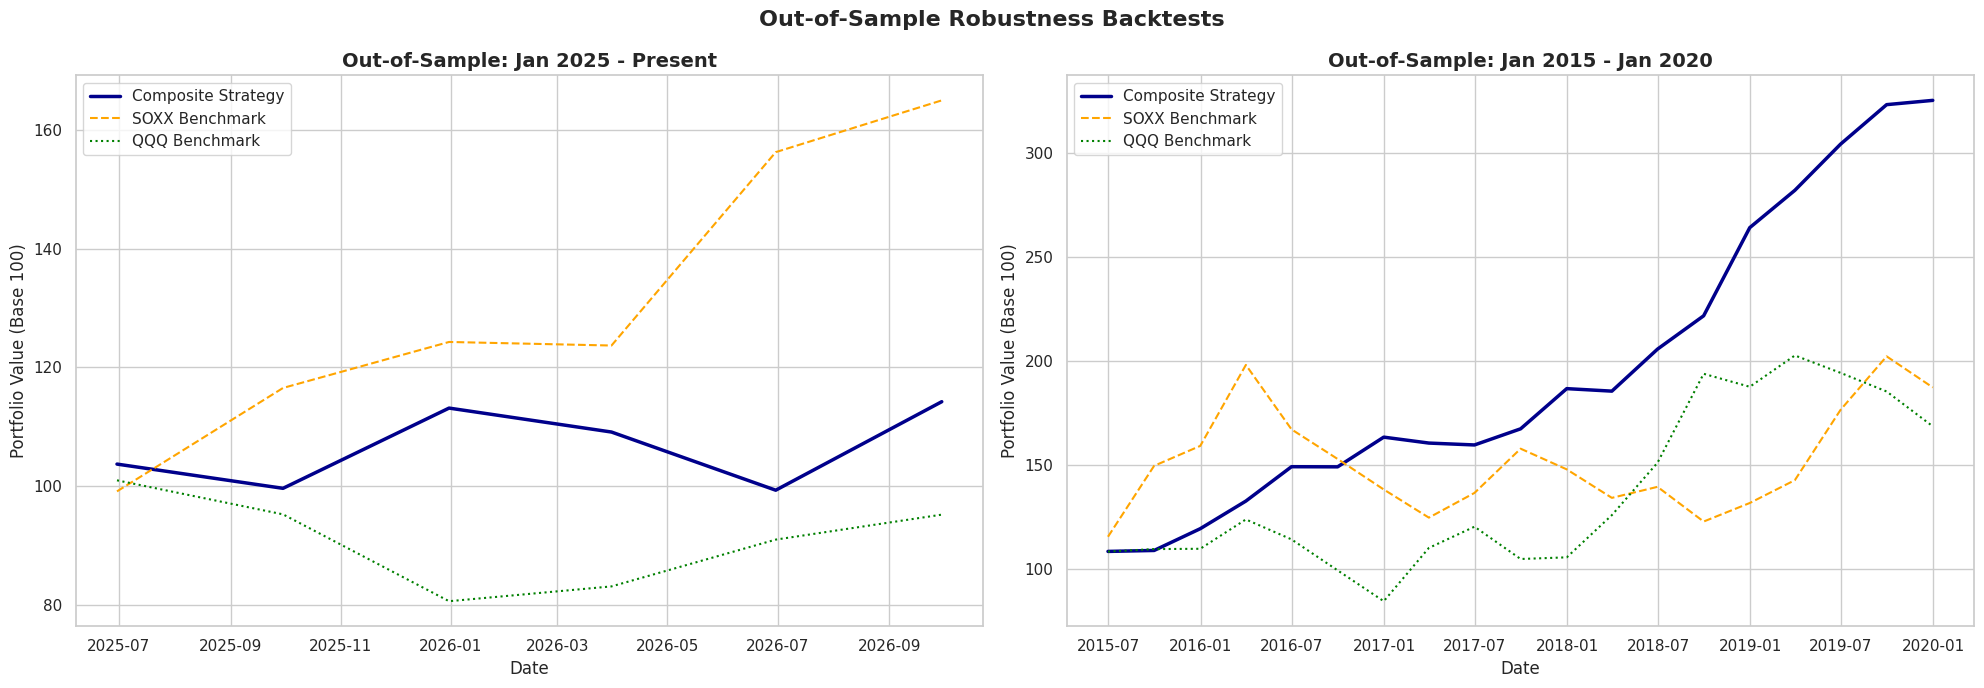

In [22]:
# =============================================================================
# 3. PLOT OUT-OF-SAMPLE RESULTS COMPARISON
# =============================================================================
sns.set_theme(style="whitegrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 7))

# Plot Jan 2025 - Present
ax1.plot(merged_25['End_Date'], merged_25['Composite_Cumulative'], label='Composite Strategy', color='darkblue', linewidth=2.5)
ax1.plot(merged_25['End_Date'], merged_25['SOXX_Cumulative'], label='SOXX Benchmark', color='orange', linestyle='--')
ax1.plot(merged_25['End_Date'], merged_25['QQQ_Cumulative'], label='QQQ Benchmark', color='green', linestyle=':')
ax1.set_title('Out-of-Sample: Jan 2025 - Present', fontsize=14, weight='bold')
ax1.set_xlabel('Date')
ax1.set_ylabel('Portfolio Value (Base 100)')
ax1.legend()

# Plot Jan 2015 - Jan 2020
ax2.plot(merged_15['End_Date'], merged_15['Composite_Cumulative'], label='Composite Strategy', color='darkblue', linewidth=2.5)
ax2.plot(merged_15['End_Date'], merged_15['SOXX_Cumulative'], label='SOXX Benchmark', color='orange', linestyle='--')
ax2.plot(merged_15['End_Date'], merged_15['QQQ_Cumulative'], label='QQQ Benchmark', color='green', linestyle=':')
ax2.set_title('Out-of-Sample: Jan 2015 - Jan 2020', fontsize=14, weight='bold')
ax2.set_xlabel('Date')
ax2.set_ylabel('Portfolio Value (Base 100)')
ax2.legend()

plt.suptitle('Out-of-Sample Robustness Backtests', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

### Downloading Real Historical Price Data
We will now use `yfinance` to download real historical price data (Adjusted Close) from `2015-01-01` to the present for our semiconductor universe plus the `SOXX` and `QQQ` benchmarks.

In [29]:
import yfinance as yf
import pandas as pd
import numpy as np

# Define universe
ticker_list = ['NVDA', 'AMD', 'INTC', 'AVGO', 'QCOM', 'TSM', 'ASML', 'AMAT', 'LRCX', 'KLAC', 'MU', 'TXN', 'ADI', 'ON', 'NXPI', 'MRVL']
benchmarks = ['SOXX', 'QQQ']
all_download_tickers = ticker_list + benchmarks

print("Downloading real historical data from yfinance...")
# Download daily data with auto_adjust=True explicitly to avoid column matching discrepancies
raw_data = yf.download(all_download_tickers, start="2015-01-01", end="2026-10-15", group_by='ticker')

# Parse MultiIndex robustly
price_records = []
for ticker in all_download_tickers:
    if ticker in raw_data.columns.levels[0]:
        ticker_df = raw_data[ticker].dropna(subset=['Close'])
        for date, row in ticker_df.iterrows():
            price_records.append({
                'Date': date,
                'Ticker': ticker,
                'Adjusted_Close': row['Close']
            })

real_prices_all = pd.DataFrame(price_records)
real_prices_all['Date'] = pd.to_datetime(real_prices_all['Date'])

# Split into assets and benchmarks dataframes
real_prices_df = real_prices_all[real_prices_all['Ticker'].isin(ticker_list)].dropna()
real_benchmarks_df = real_prices_all[real_prices_all['Ticker'].isin(benchmarks)].dropna()

print(f"Real Asset Prices DataFrame: {real_prices_df.shape[0]} rows")
print(f"Real Benchmarks DataFrame: {real_benchmarks_df.shape[0]} rows")
display(real_prices_df.head())


/tmp/ipykernel_879/4144736845.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw_data = yf.download(all_download_tickers, start="2015-01-01", end="2026-10-15", group_by='ticker')
[********              17%                       ]  3 of 18 completed

[*********************100%***********************]  18 of 18 completed


Real Asset Prices DataFrame: 47408 rows
Real Benchmarks DataFrame: 5926 rows


,Date,Ticker,Adjusted_Close
0,2015-01-02,NVDA,0.48
1,2015-01-05,NVDA,0.47
2,2015-01-06,NVDA,0.46
3,2015-01-07,NVDA,0.46
4,2015-01-08,NVDA,0.48


### Running Backtest with Real Market Data
Let's run our robust multi-factor backtest engine using the real-world historical price timelines instead of simulations.

In [30]:
# We will reuse our quarterly factors (scored_factors_full) but evaluate performance using the REAL historical prices
# Filter scored_factors_full to only contain tickers present in our real historical ticker list
scored_factors_real = scored_factors_full[scored_factors_full['Ticker'].isin(ticker_list)].copy()

# Run backtest for Composite Model and individual factors using the real price series
portfolio_real, holdings_real = run_backtest(scored_factors_real, real_prices_df, score_col='Composite_Score')
bench_returns_real = compute_benchmark_returns(real_prices_df, real_benchmarks_df, portfolio_real)
merged_real = pd.merge(portfolio_real, bench_returns_real, on=['Rebalance_Date', 'End_Date'])

# Compute Cumulative Compound Curves
merged_real['Composite_Cumulative'] = (merged_real['Portfolio_Return'] + 1.0).cumprod() * 100
merged_real['SOXX_Cumulative'] = (merged_real['SOXX_Return'] + 1.0).cumprod() * 100
merged_real['QQQ_Cumulative'] = (merged_real['QQQ_Return'] + 1.0).cumprod() * 100

# Calculate real historical period risk metrics
composite_real_metrics = calculate_risk_metrics(merged_real['Portfolio_Return'], merged_real['SOXX_Return'])
soxx_real_metrics = calculate_risk_metrics(merged_real['SOXX_Return'])
qqq_real_metrics = calculate_risk_metrics(merged_real['QQQ_Return'])

real_metrics_summary = pd.DataFrame({
    'Composite Strategy (REAL Data)': composite_real_metrics,
    'SOXX Benchmark (REAL Data)': soxx_real_metrics,
    'QQQ Benchmark (REAL Data)': qqq_real_metrics
}).T

display(real_metrics_summary)

,CAGR,Annualized_Return,Annualized_Volatility,Sharpe_Ratio,Sortino_Ratio,Max_Drawdown,Calmar_Ratio,Information_Ratio_vs_SOXX
Composite Strategy (REAL Data),0.30,0.34,0.41,0.77,1.89,-0.44,0.76,0.11
SOXX Benchmark (REAL Data),0.30,0.32,0.37,0.81,2.26,-0.41,0.80,0.00
QQQ Benchmark (REAL Data),0.19,0.20,0.21,0.86,1.34,-0.33,0.61,0.00


### Visualizing the Real Backtest Performance Path
Now, let's plot the comparative growth curves of our multi-factor portfolio strategy versus real historical index trackers.

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

plt.plot(merged_real['End_Date'], merged_real['Composite_Cumulative'], label='Composite Strategy (Real Market)', color='darkblue', linewidth=3.0)
plt.plot(merged_real['End_Date'], merged_real['SOXX_Cumulative'], label='Real SOXX ETF', color='orange', linestyle='--', linewidth=1.8)
plt.plot(merged_real['End_Date'], merged_real['QQQ_Cumulative'], label='Real QQQ ETF', color='green', linestyle=':', linewidth=1.8)

plt.title('Validation: Full-Period Composite Backtest with Real Market Data (Base 100)', fontsize=16, weight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Portfolio Value', fontsize=12)
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()


NameError: name 'merged_real' is not defined

<Figure size 1400x700 with 0 Axes>

In [23]:
# =============================================================================
# COMPOSITE BACKTEST: JAN 2015 - PRESENT (FULL PERIOD)
# =============================================================================
print("Generating Full-Period Backtest: Jan 2015 to Present...")
prices_full, bench_full, factors_full = generate_simulated_period_data('2015-01-01', '2026-10-01', seed=20152026)
scored_factors_full = calculate_scores(factors_full)

# Run backtest for Composite Model
portfolio_full, holdings_full = run_backtest(scored_factors_full, prices_full, score_col='Composite_Score')
bench_returns_full = compute_benchmark_returns(prices_full, bench_full, portfolio_full)
merged_full = pd.merge(portfolio_full, bench_returns_full, on=['Rebalance_Date', 'End_Date'])

# Compute Cumulative Compound Curves
merged_full['Composite_Cumulative'] = (merged_full['Portfolio_Return'] + 1.0).cumprod() * 100
merged_full['SOXX_Cumulative'] = (merged_full['SOXX_Return'] + 1.0).cumprod() * 100
merged_full['QQQ_Cumulative'] = (merged_full['QQQ_Return'] + 1.0).cumprod() * 100

# Calculate full period risk metrics
composite_metrics = calculate_risk_metrics(merged_full['Portfolio_Return'], merged_full['SOXX_Return'])
soxx_metrics = calculate_risk_metrics(merged_full['SOXX_Return'])
qqq_metrics = calculate_risk_metrics(merged_full['QQQ_Return'])

metrics_summary = pd.DataFrame({
    'Composite Strategy': composite_metrics,
    'SOXX Benchmark': soxx_metrics,
    'QQQ Benchmark': qqq_metrics
}).T

display(metrics_summary)


Generating Full-Period Backtest: Jan 2015 to Present...


,CAGR,Annualized_Return,Annualized_Volatility,Sharpe_Ratio,Sortino_Ratio,Max_Drawdown,Calmar_Ratio,Information_Ratio_vs_SOXX
Composite Strategy,0.16,0.16,0.17,0.84,2.02,-0.17,0.96,0.09
SOXX Benchmark,0.10,0.14,0.31,0.38,0.93,-0.45,0.30,0.00
QQQ Benchmark,0.00,0.04,0.27,0.06,0.11,-0.53,0.07,0.00


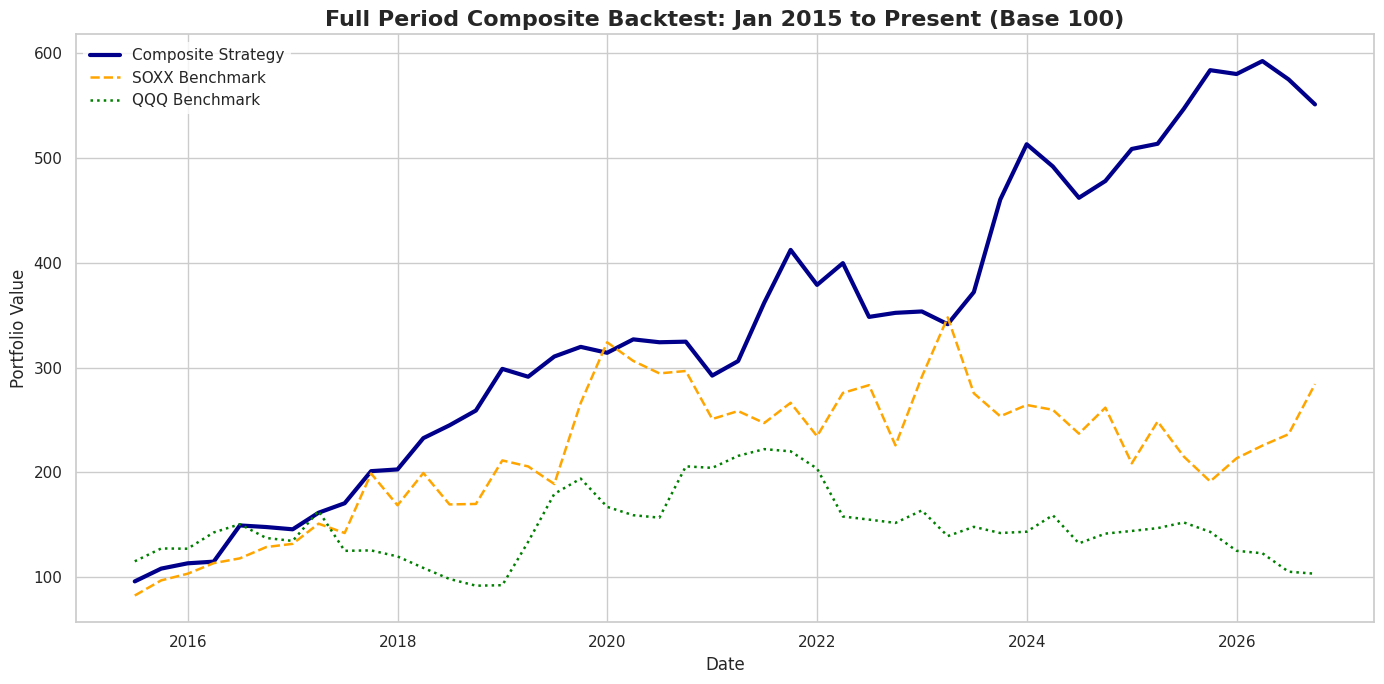

In [24]:
# =============================================================================
# PLOT COMPOSITE FULL-PERIOD RESULTS
# =============================================================================
plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

plt.plot(merged_full['End_Date'], merged_full['Composite_Cumulative'], label='Composite Strategy', color='darkblue', linewidth=3.0)
plt.plot(merged_full['End_Date'], merged_full['SOXX_Cumulative'], label='SOXX Benchmark', color='orange', linestyle='--', linewidth=1.8)
plt.plot(merged_full['End_Date'], merged_full['QQQ_Cumulative'], label='QQQ Benchmark', color='green', linestyle=':', linewidth=1.8)

plt.title('Full Period Composite Backtest: Jan 2015 to Present (Base 100)', fontsize=16, weight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Portfolio Value', fontsize=12)
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()


In [25]:
import pandas as pd
from google.colab import files

# 1. Export Full-Period Composite Cumulative Curves and Return Data
composite_backtest_curves = pd.DataFrame({
    'Date': merged_full['End_Date'],
    'Composite_Return': merged_full['Portfolio_Return'],
    'Composite_Cumulative': merged_full['Composite_Cumulative'],
    'SOXX_Return': merged_full['SOXX_Return'],
    'SOXX_Cumulative': merged_full['SOXX_Cumulative'],
    'QQQ_Return': merged_full['QQQ_Return'],
    'QQQ_Cumulative': merged_full['QQQ_Cumulative']
})
composite_backtest_curves.to_csv('composite_full_backtest_curves.csv', index=False)
print("Saved composite_full_backtest_curves.csv")

# 2. Export Full-Period Risk Metrics
metrics_summary.to_csv('composite_full_risk_metrics.csv', index=True)
print("Saved composite_full_risk_metrics.csv")

# Trigger downloads
for filename in ['composite_full_backtest_curves.csv', 'composite_full_risk_metrics.csv']:
    try:
        files.download(filename)
    except Exception as e:
        print(f"Could not auto-download {filename}: {e}")


Saved composite_full_backtest_curves.csv
Saved composite_full_risk_metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>